<a href="https://colab.research.google.com/github/edwin-yucras/ALT/blob/main/Day4_LULC_and_Climate_with_RS/04_climate_products_et_and_water_balance_es.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ScriptsRemote/Transcend_SummerSchool/blob/main/Day4_LULC_and_Climate_with_RS/04_climate_products_et_and_water_balance_es.ipynb)

# Día 4 - Uso y Cobertura del Suelo y Clima con Teledetección
## Sesión 4: Productos climáticos, ET y balance hídrico

| | |
|---|---|
| **Fecha** | 2026-10-15 (jueves) |
| **Horario** | 15:40 - 17:10 |
| **Entidad** | UoM |
| **Instructores** | Christhian |

### Contenido

> Productos climáticos de observación de la Tierra (CHIRPS, GSMaP, IMERG, ERA5-Land). El producto de ET MODIS MOD16
> (estructura, escalado, resolución). Series temporales mensuales, balance hídrico simplificado
> (P - ET), estadísticas zonales y análisis de tendencias para la cuenca del Lago Titicaca.

### Objetivos de aprendizaje

- [ ] Escribir la ecuación del balance hídrico y explicar qué representa el **P - ET** simplificado
- [ ] Comparar los principales productos satelitales de **precipitación** según su resolución espacial y temporal,
      la longitud del registro y el método
- [ ] Explicar cómo se estima la **evapotranspiración** desde el espacio y conocer los principales conjuntos de datos de ET,
      dentro y fuera de Google Earth Engine
- [ ] Construir colecciones mensuales de P, ET y P - ET en GEE (CHIRPS + MOD16A2GF), extraer la
      media de la cuenca como un `DataFrame` y graficar series mensuales y anuales con una línea de tendencia

### Datos necesarios

- `UCSB-CHG/CHIRPS/DAILY` y `MODIS/061/MOD16A2GF` del catálogo de Earth Engine
- El límite de la cuenca `projects/ee-christhianscunha/assets/transcend/basin_Titicaca`
  (sistema Lago Titicaca - Desaguadero - Poopó)

### Lo que ya vimos

Los Días 2 y 3 cubrieron colecciones de imágenes, filtros, reductores y estadísticas zonales. Esta sesión
los aplica a **series temporales climáticas** en lugar de a una sola imagen.

---

## 4.1 - Teoría: el balance hídrico

El balance hídrico es la **contabilidad del agua** que entra y sale de un área - una parcela,
una cuenca, un lago - durante un período de tiempo:

$$P = ET + Q + \Delta S$$

| Término | Significado | Fuente típica |
|---|---|---|
| $P$ | **Precipitación** - lluvia, nieve, granizo | pluviómetros, satélites, reanálisis |
| $ET$ | **Evapotranspiración** - agua devuelta a la atmósfera | modelos alimentados con datos satelitales |
| $Q$ | **Escorrentía** - agua que sale del área por los ríos (y por el agua subterránea) | estaciones de aforo |
| $\Delta S$ | **Cambio de almacenamiento** - humedad del suelo, agua subterránea, lagos, nieve | GRACE, niveles de lagos, humedad del suelo |

### El balance simplificado: P - ET

$Q$ y $\Delta S$ son difíciles de medir en todas partes. P y ET, en cambio, están disponibles como
productos globales en grilla. Su diferencia

$$P - ET = Q + \Delta S$$

es el agua que **queda** después de que la atmósfera toma su parte:

- **P - ET > 0** - excedente: agua disponible para recargar suelos y acuíferos y para alimentar los ríos
  y el lago;
- **P - ET < 0** - déficit: la superficie pierde más de lo que recibe, y la diferencia viene
  del **almacenamiento** (suelo, agua subterránea, el propio lago).

En un año completo $\Delta S$ suele ser cercano a cero, así que el P - ET anual es una estimación del
**rendimiento hídrico** de la cuenca.

### Unidades

Todo se expresa como una **lámina de agua en mm** por período (mm/mes, mm/año).
1 mm sobre 1 m² es 1 litro; **1 mm sobre 1 km² = 1,000 m³**. Esto hace que P, ET y P - ET sean
directamente comparables y fáciles de convertir en volúmenes.

### El contexto del Titicaca

El altiplano tiene un clima fuertemente **estacional**: la mayor parte de la lluvia cae entre diciembre y
marzo, y de mayo a septiembre es casi seco. Por lo tanto, el P - ET mensual es positivo en la época
húmeda y negativo en la época seca. El propio Lago Titicaca pierde la mayor parte de su agua por
**evaporación** - solo una pequeña parte sale por el río Desaguadero - así que pequeños cambios en
P o ET tienen un efecto directo en el nivel del lago.

---

## 4.2 - Teoría: precipitación desde el espacio

### Cómo se estima la precipitación

| Fuente | Cómo funciona | Fortaleza | Limitación |
|---|---|---|---|
| **Pluviómetros** | medición directa en un punto | la referencia ("verdad") | pocas estaciones, sobre todo en los Andes |
| **Infrarrojo (IR)** - satélites geoestacionarios | topes de nubes fríos = lluvia probable | cada 10-30 min, registros largos | indirecto: las nubes frías no siempre producen lluvia |
| **Microondas pasivas (PMW)** - satélites polares | señal de las gotas de lluvia y el hielo dentro de la nube | físicamente más cercano a la lluvia | pocos pasos por día |
| **Radar** - GPM Core Observatory | estructura 3D de la lluvia | el más preciso desde el espacio | barrido estrecho, solo para calibración |
| **Reanálisis** - ERA5 | modelo meteorológico + todas las observaciones | completo en el espacio y el tiempo, muchas variables | grueso; es un modelo, no una observación |

Los productos globales **combinan** estas fuentes: el IR da la frecuencia, las PMW dan la intensidad
de la lluvia, y los pluviómetros corrigen el sesgo.

### Principales productos en Google Earth Engine

| Producto | ID en GEE | Píxel | Paso de tiempo | Registro | Método |
|---|---|---|---|---|---|
| **CHIRPS v2** | `UCSB-CHG/CHIRPS/DAILY` | 0.05° (~5.5 km) | diario | 1981 - presente | IR + climatología + **pluviómetros**, 50°S-50°N |
| **CHIRPS v3** | `UCSB-CHC/CHIRPS/V3/DAILY_RNL` | 0.05° (~5.5 km) | diario | 1981 - presente | nueva versión, 60°S-60°N, desagregación diaria con ERA5 |
| **GSMaP v8** | `JAXA/GPM_L3/GSMaP/v8/operational` | 0.1° (~11 km) | **horario** | 1998 - presente | PMW + IR (JAXA) |
| **IMERG V07** | `NASA/GPM_L3/IMERG_V07` | 0.1° (~11 km) | **30 min** | 1998 - presente | PMW + IR + pluviómetros (NASA) |
| **ERA5-Land** | `ECMWF/ERA5_LAND/MONTHLY_AGGR` | 0.1° (~11 km) | horario / mensual | 1950 - presente | reanálisis (modelo) |
| **TerraClimate** | `IDAHO_EPSCOR/TERRACLIMATE` | ~4 km | mensual | 1958 - presente | climatología + reanálisis |
| **PERSIANN-CDR** | `NOAA/PERSIANN-CDR` | 0.25° (~27 km) | diario | 1983 - presente | IR + red neuronal, ajustado con pluviómetros |

### Cómo elegir

- **Detalle espacial** - CHIRPS y TerraClimate (~5 km) muestran más detalle que los productos de 0.1°;
  esto importa en las montañas, donde la lluvia cambia en distancias cortas.
- **Detalle temporal** - para tormentas e inundaciones se necesitan horas (GSMaP, IMERG); para balances
  mensuales, los productos diarios o mensuales son suficientes.
- **Longitud del registro** - para tendencias y normales climáticas (30 años) use CHIRPS, ERA5-Land o
  TerraClimate.
- **Unidades** - verifíquelas siempre: CHIRPS está en mm/día, GSMaP e IMERG en **mm/hora**, ERA5-Land
  está en **metros**. Un total mensual es la **suma** de los valores diarios (u horarios).

> **En los Andes**, todos los productos tienen errores mayores: terreno complejo, tormentas convectivas, granizo
> y pocos pluviómetros para corregirlos. Siempre que sea posible, **compare con estaciones locales**
> (SENAMHI Bolivia / Perú) antes de confiar en un solo producto.

En la práctica usamos **CHIRPS**: diario, ~5.5 km y corregido con pluviómetros.

---

## 4.3 - Teoría: evapotranspiración (ET)

La **evapotranspiración** es la suma de dos procesos que devuelven agua a la atmósfera:

- **Evaporación (E)** - desde el suelo, el agua libre y las superficies mojadas;
- **Transpiración (T)** - agua absorbida por las raíces y liberada a través de las hojas.

No se deben confundir dos conceptos:

- **ET potencial (PET)** - cuánto **podría** evaporarse si el agua fuera ilimitada; depende solo de
  la atmósfera (radiación, temperatura, viento, humedad).
- **ET real (AET o ETa)** - cuánto se evapora **realmente**; limitada por el agua disponible
  en el suelo y por la vegetación. **El balance hídrico usa la ET real.**

En el altiplano la PET es alta (radiación fuerte, aire seco), pero en la época seca la ET real es
baja porque queda poca agua en el suelo.

### Cómo se estima la ET desde el espacio

Un satélite no puede ver la ET directamente. Se **modela** a partir de variables que se pueden
observar:

| Enfoque | Idea | Ejemplos |
|---|---|---|
| **Penman-Monteith** | energía + vegetación (LAI, albedo) + datos meteorológicos | MOD16, PML_V2 |
| **Balance de energía en superficie** (banda térmica) | la energía que no se usa para calentar la superficie se usa para evaporar agua: una superficie más fría evapora más | SEBAL, METRIC, **SSEBop** (Landsat) |
| **Modelos de superficie terrestre / reanálisis** | un modelo hidrológico ejecutado con datos meteorológicos | GLDAS, FLDAS, ERA5-Land, TerraClimate |

### MOD16 - el producto que usamos

`MODIS/061/MOD16A2GF` es la versión **con vacíos rellenados** (gap-filled) de MOD16A2 (satélite Terra):

| Propiedad | Valor |
|---|---|
| Píxel | **500 m** |
| Paso de tiempo | **composición de 8 días** - cada imagen es el **total** de ET de 8 días (la última del año tiene 5 o 6) |
| Banda | `ET`, unidades **kg/m²/8 días** = mm/8 días |
| Factor de escala | **0.1** - multiplicar antes de usar |
| Relleno de vacíos | se hace una vez por año, al final del año - por eso pueden faltar los meses más recientes |
| Áreas enmascaradas | **sin valores sobre agua, áreas urbanas y superficies estériles** - incluido el Lago Titicaca |

El último punto es importante para la práctica: MOD16 **no tiene ET para el lago**, así que calculamos
el balance solo sobre los píxeles donde MOD16 tiene datos (la parte terrestre de la cuenca).

### Principales conjuntos de datos de ET en Google Earth Engine

| Conjunto de datos | ID en GEE | Píxel | Paso de tiempo | Cobertura | Método |
|---|---|---|---|---|---|
| **MOD16A2GF v061** | `MODIS/061/MOD16A2GF` | 500 m | 8 días | global, 2000 - último año completo | Penman-Monteith, con vacíos rellenados |
| **MOD16A2 v061** | `MODIS/061/MOD16A2` | 500 m | 8 días | global, casi en tiempo real | Penman-Monteith (con vacíos) |
| **PML_V2.2a** | `projects/pml_evapotranspiration/PML/OUTPUT/PML_V22a` | 500 m | 8 días | global | Penman-Monteith-Leuning, acoplado con GPP |
| **TerraClimate** | `IDAHO_EPSCOR/TERRACLIMATE` (banda `aet`) | ~4 km | mensual | global, 1958 - | modelo de balance hídrico |
| **ERA5-Land** | `ECMWF/ERA5_LAND/MONTHLY_AGGR` | ~11 km | mensual | global, 1950 - | reanálisis (la evaporación es **negativa**, en metros) |
| **FLDAS** | `NASA/FLDAS/NOAH01/C/GL/M/V001` | ~11 km | mensual | global, 1982 - | modelo de superficie terrestre |
| **GLDAS-2.1** | `NASA/GLDAS/V021/NOAH/G025/T3H` | ~28 km | cada 3 horas | global, 2000 - | modelo de superficie terrestre |
| **OpenET** | `projects/openet/...` | **30 m** | mensual | **solo EE. UU.** | conjunto (ensemble) de modelos basados en Landsat |

### ET con Landsat - fuera de Google Earth Engine

A 500 m, un píxel MOD16 mezcla parcelas, caminos y casas. Para el trabajo **a escala de parcela** (riego,
cultivos) se necesita la ET a la resolución de Landsat:

- **Landsat Collection 2 Level-3 Provisional Actual Evapotranspiration** (USGS) - ET real diaria
  en mm para la fecha de cada escena Landsat, a **30 m**, calculada con el modelo de balance de energía
  en superficie **SSEBop** a partir de la banda térmica. La cobertura es **global**, pero el producto **no
  está en el catálogo de GEE**: se solicita escena por escena a través de la interfaz a pedido
  USGS ESPA. En EE. UU., la ET mensual equivalente basada en Landsat está disponible en GEE a través de
  OpenET.
- Otros productos conocidos fuera de GEE: **GLEAM** (global, ~25 km / ~10 km, diario) y **WaPOR** de la FAO
  (África y Cercano Oriente, de 250 m hasta 30 m).

> **Compensación.** La ET de Landsat tiene un detalle fino pero solo un valor cada 8-16 días (y ninguno bajo
> nubes). MOD16 tiene una imagen cada 8 días pero a 500 m. Para un balance hídrico mensual de una
> cuenca grande como la del Titicaca, MOD16 es la opción práctica.

---

## 4.4 - Práctica guiada: balance hídrico de la cuenca del Titicaca

Flujo de trabajo (adaptado del libro *Cloud-Based Remote Sensing with Google Earth Engine*):

1. cuenca y período;
2. CHIRPS (P) y MOD16 (ET), con el factor de escala;
3. P, ET y P - ET **mensuales** como una sola colección de imágenes;
4. media de la cuenca de cada mes -> `DataFrame`;
5. gráficos: balance mensual, P y ET mensuales, totales anuales con tendencia;
6. mapas de P, ET y P - ET medios anuales.

In [18]:
# Librerías (descomente la línea de pip en un entorno nuevo, p. ej. Google Colab)
#%pip install -q earthengine-api geemap

import ee                          # API de Google Earth Engine
import geemap                      # mapas interactivos para Earth Engine
import numpy as np                 # línea de tendencia
import pandas as pd                # tablas (DataFrames)
import matplotlib.pyplot as plt    # gráficos

In [19]:
# Autenticar e inicializar Earth Engine
# >>> REEMPLAZAR por el id de su propio proyecto de Cloud <<<
EE_PROJECT = "ee-edwinyucra"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

### Cuenca y período

In [4]:
# Cuenca del Lago Titicaca (sistema TDP)
roi = ee.FeatureCollection("projects/ee-christhianscunha/assets/transcend/basin_Titicaca")
basin = roi.geometry()

# Período: años completos
START_YEAR, END_YEAR = 2020, 2025
start = ee.Date.fromYMD(START_YEAR, 1, 1)
end = ee.Date.fromYMD(END_YEAR + 1, 1, 1)      # 1 de enero del año siguiente

Map = geemap.Map()
Map.centerObject(roi, 7)
Map.addLayer(roi.style(color="red", fillColor="00000000", width=2), {}, "Lake Titicaca watershed")
Map

Map(center=[-16.69684895196021, -68.9231537015214], controls=(WidgetControl(options=['position', 'transparent_…

### Precipitación (CHIRPS) y ET (MOD16)

- CHIRPS: banda `precipitation`, **mm/día** - sin factor de escala.
- MOD16A2GF: banda `ET`, **kg/m²/8 días** con factor de escala **0.1** -> mm/8 días.

In [5]:
# Precipitación: CHIRPS diario (mm/día)
chirps = (ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
            .select("precipitation")
            .filterDate(start, end))


def scale_mod16(image):
    # Factor de escala 0.1 -> mm por 8 días; conservar la fecha de la imagen
    return image.multiply(0.1).copyProperties(image, ["system:time_start"])


# Evapotranspiración: composiciones de 8 días de MOD16A2GF (mm/8 días)
mod16 = (ee.ImageCollection("MODIS/061/MOD16A2GF")
           .select("ET")
           .filterDate(start, end)
           .map(scale_mod16))

print("CHIRPS images:", chirps.size().getInfo())
print("MOD16 images :", mod16.size().getInfo())
print("Last MOD16 date:", ee.Date(mod16.aggregate_max("system:time_start")).format("YYYY-MM-dd").getInfo())

CHIRPS images: 2192
MOD16 images : 276
Last MOD16 date: 2025-12-27


### P, ET y P - ET mensuales

Para cada mes **sumamos** todas las imágenes diarias de CHIRPS y todas las composiciones de MOD16 que comienzan en ese
mes, y las restamos. Una función construye las tres bandas de un mes; `map()` la aplica
a cada mes del período.

Dos detalles:

- P se enmascara con la máscara de ET (`updateMask`), de modo que ambas se calculan sobre los **mismos píxeles**
  (MOD16 no tiene datos sobre el lago ni sobre las áreas urbanas).
- Sumar las composiciones de 8 días que **comienzan** en un mes es una aproximación: un mes recibe 3 o
  4 composiciones, y una composición puede pasar al mes siguiente. Para balances mensuales y anuales
  el error es pequeño, pero aparece como ruido de un mes a otro.

In [6]:
def monthly_balance(i):
    # Primer y último día del mes número i del período
    month_start = start.advance(i, "month")
    month_end = month_start.advance(1, "month")

    # Totales mensuales (mm/mes)
    et = mod16.filterDate(month_start, month_end).sum().rename("ET")
    p = chirps.filterDate(month_start, month_end).sum().rename("precipitation")
    p = p.updateMask(et.mask())                           # los mismos píxeles que la ET

    # Balance hídrico simplificado
    wb = p.subtract(et).rename("water_balance")

    return (p.addBands([et, wb])
             .set("system:time_start", month_start.millis())
             .set("year", month_start.get("year"))
             .set("month", month_start.get("month")))


# Una imagen por mes: 6 años x 12 meses = 72 imágenes
n_months = (END_YEAR - START_YEAR + 1) * 12
monthly = ee.ImageCollection(ee.List.sequence(0, n_months - 1).map(monthly_balance))

print("Monthly images:", monthly.size().getInfo())
print("Bands         :", monthly.first().bandNames().getInfo())

Monthly images: 72
Bands         : ['precipitation', 'ET', 'water_balance']


### Estadísticas zonales: media de la cuenca de cada mes

`reduceRegion` con el reductor de **media** da un valor por banda y por mes para toda la
cuenca. Guardamos cada resultado como un `Feature` y convertimos la colección en un `DataFrame`
con geemap.

In [7]:
def watershed_mean(image):
    # Media de P, ET y P - ET sobre la cuenca (500 m = píxel de MOD16)
    stats = image.reduceRegion(reducer=ee.Reducer.mean(), geometry=basin,
                               scale=500, maxPixels=1e10, tileScale=4)
    return ee.Feature(None, stats).set("date", image.date().format("YYYY-MM-dd"))


table = ee.FeatureCollection(monthly.map(watershed_mean))

# A un DataFrame, ordenado por fecha
df = geemap.ee_to_df(table)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").set_index("date")[["precipitation", "ET", "water_balance"]]

df.round(1).head(12)

,precipitation,ET,water_balance
date,,,
2020-01-01,64.6,68.9,-4.2
2020-02-01,139.0,73.7,65.3
2020-03-01,96.9,62.4,34.5
2020-04-01,13.5,37.7,-24.2
2020-05-01,18.6,18.1,0.5
2020-06-01,4.4,26.5,-22.1
2020-07-01,3.0,19.9,-16.9
2020-08-01,7.0,31.9,-25.0
2020-09-01,38.9,39.7,-0.8


### Gráfico 1 - Balance hídrico mensual

Barras: P - ET (positivo = excedente, negativo = déficit). Líneas: P y ET.

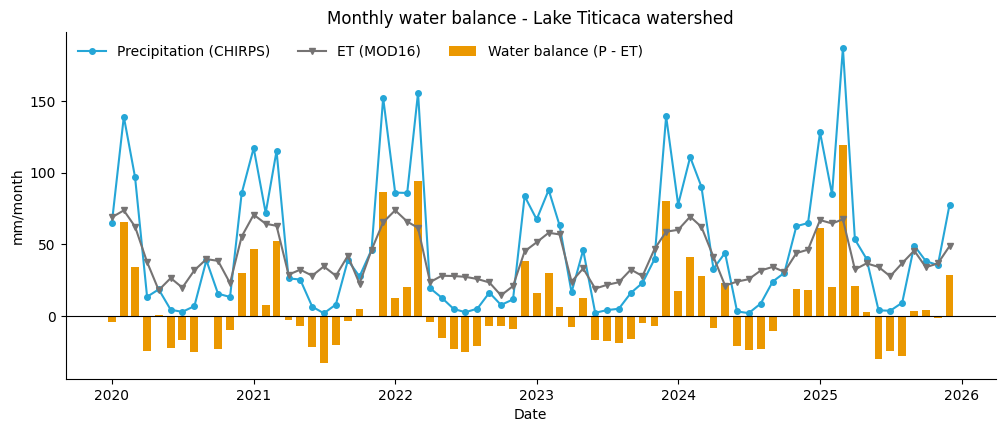

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.5))

# P - ET como barras, P y ET como líneas
ax.bar(df.index, df["water_balance"], width=20, color="#eb9800", label="Water balance (P - ET)")
ax.plot(df.index, df["precipitation"], color="#25a6d7", marker="o", markersize=4, label="Precipitation (CHIRPS)")
ax.plot(df.index, df["ET"], color="#757373", marker="v", markersize=4, label="ET (MOD16)")
ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Monthly water balance - Lake Titicaca watershed")
ax.set_xlabel("Date")
ax.set_ylabel("mm/month")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Cómo leerlo.** Cada año repite el mismo patrón: un **excedente** en la época de lluvias
(diciembre-marzo), cuando P está muy por encima de la ET, y un **déficit** de mayo a octubre, cuando la ET
continúa pero la lluvia se detiene. Compare la altura de las barras de la época de lluvias de un año a otro - una
época de lluvias débil significa menos agua para recargar el sistema y el lago.

### Gráfico 2 - Precipitación y ET mensuales

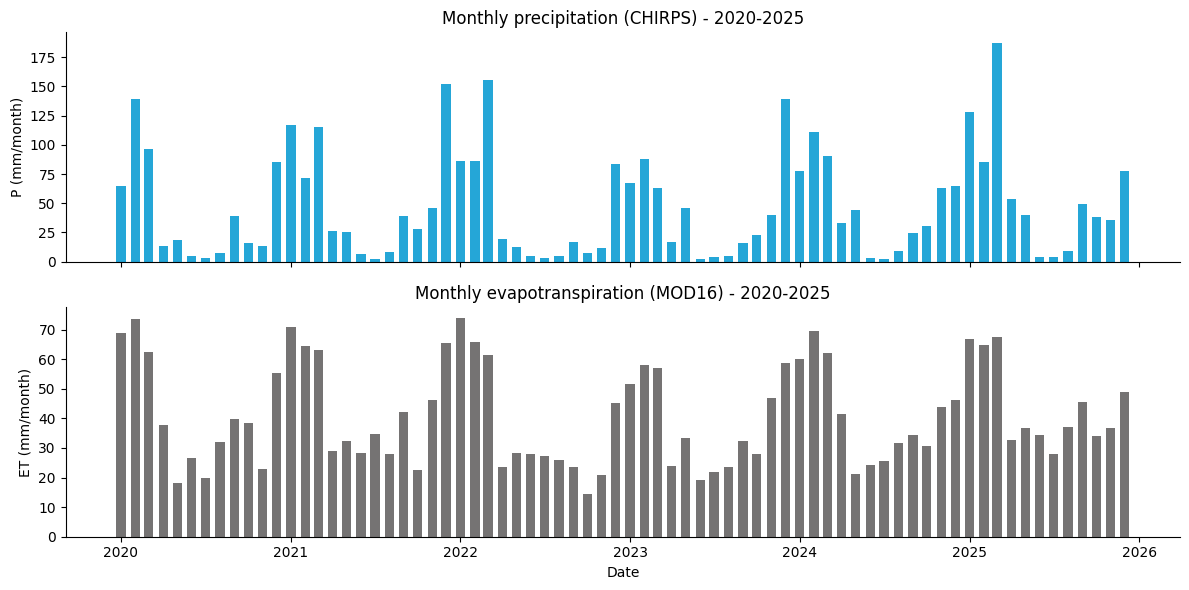

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Precipitación mensual
ax1.bar(df.index, df["precipitation"], width=20, color="#25a6d7")
ax1.set_title(f"Monthly precipitation (CHIRPS) - {START_YEAR}-{END_YEAR}")
ax1.set_ylabel("P (mm/month)")

# Evapotranspiración mensual
ax2.bar(df.index, df["ET"], width=20, color="#757373")
ax2.set_title(f"Monthly evapotranspiration (MOD16) - {START_YEAR}-{END_YEAR}")
ax2.set_ylabel("ET (mm/month)")
ax2.set_xlabel("Date")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Observe que **la ET sigue a la P con un retraso**: sube con las primeras lluvias y se mantiene relativamente
alta durante algunos meses después de que la lluvia se detiene, mientras el suelo y la vegetación todavía tienen agua.

### Gráfico 3 - Totales anuales y tendencia

Los totales anuales son la **suma** de los 12 meses. Una línea recta ajustada con `np.polyfit` muestra
la dirección del cambio (mm por año).

In [10]:
# Totales anuales (mm/año)
annual = df.groupby(df.index.year).sum()
annual.index.name = "year"
annual.round(0)

,precipitation,ET,water_balance
year,,,
2020,500.0,496.0,5.0
2021,638.0,527.0,111.0
2022,492.0,438.0,54.0
2023,511.0,454.0,57.0
2024,552.0,492.0,60.0
2025,711.0,533.0,178.0


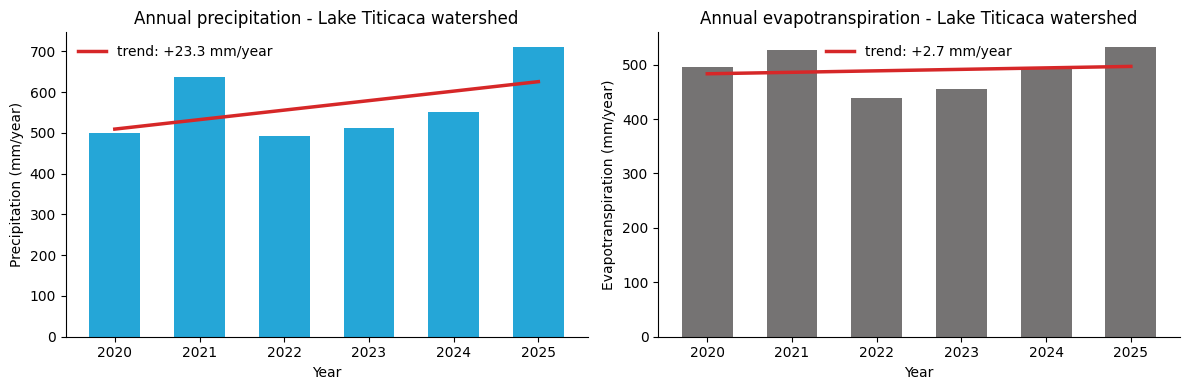

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, band, colour, name in [(axes[0], "precipitation", "#25a6d7", "Precipitation"),
                               (axes[1], "ET", "#757373", "Evapotranspiration")]:
    # Barras: total anual
    ax.bar(annual.index, annual[band], color=colour, width=0.6)

    # Tendencia lineal: pendiente en mm/año
    slope, intercept = np.polyfit(annual.index, annual[band], 1)
    ax.plot(annual.index, slope * annual.index + intercept, color="#d62728", linewidth=2.5,
            label=f"trend: {slope:+.1f} mm/year")

    ax.set_title(f"Annual {name.lower()} - Lake Titicaca watershed")
    ax.set_xlabel("Year")
    ax.set_ylabel(f"{name} (mm/year)")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

> **Cuidado con las tendencias.** Seis años son suficientes para ver la variabilidad de un año a otro (los años de El Niño /
> La Niña son claramente diferentes) pero **no** para sacar conclusiones sobre el cambio climático. Las tendencias
> necesitan registros largos (20-30 años) y una prueba estadística, como Mann-Kendall.

### Mapas - P, ET y P - ET medios anuales

Los gráficos resumen la cuenca en un número por mes. Los mapas muestran **dónde** están el excedente
y el déficit de agua.

In [12]:
# Total anual medio = suma de todos los meses / número de años
n_years = END_YEAR - START_YEAR + 1
annual_mean = monthly.sum().divide(n_years).clip(basin)

vis_p = {"bands": ["precipitation"], "min": 300, "max": 1000,
         "palette": ["#f7fbff", "#9ecae1", "#3182bd", "#08306b"]}
vis_et = {"bands": ["ET"], "min": 100, "max": 700,
          "palette": ["#ffffcc", "#a1dab4", "#41b6c4", "#225ea8"]}
vis_wb = {"bands": ["water_balance"], "min": -300, "max": 300,
          "palette": ["#b2182b", "#f4a582", "#f7f7f7", "#92c5de", "#2166ac"]}

Map = geemap.Map()
Map.centerObject(roi, 7)
Map.addLayer(annual_mean, vis_p, "Mean annual P (mm/year)", False)
Map.addLayer(annual_mean, vis_et, "Mean annual ET (mm/year)", False)
Map.addLayer(annual_mean, vis_wb, "Mean annual P - ET (mm/year)")
Map.addLayer(roi.style(color="black", fillColor="00000000", width=1), {}, "Watershed")
Map.add_colorbar(vis_wb, label="P - ET (mm/year)")
Map

Map(center=[-16.696848951960142, -68.92315370152143], controls=(WidgetControl(options=['position', 'transparen…

Active y desactive las capas. ¿Dónde está el excedente (azul)? Normalmente cerca de las **cordilleras**
y al norte del lago, donde llueve más. ¿Dónde está el déficit (rojo)? Normalmente en el
altiplano sur, hacia el Lago Poopó, donde llueve poco y la ET es relativamente alta. El
propio lago queda en blanco: MOD16 no tiene ET sobre el agua libre.

---

---

### Balance hídrico por cobertura del suelo: agricultura y vegetación natural (MapBiomas Bolivia)

Hasta ahora promediamos toda la cuenca. Ahora preguntamos: **¿cuánto P, ET y P - ET hay
donde la gente cultiva, y cuánto en la vegetación natural?** Usamos el mapa de uso y cobertura del suelo
de **MapBiomas Bolivia - Colección 3 (1985-2024)**, el mismo asset usado por el
[MapBiomas user toolkit](https://github.com/mapbiomas/user-toolkit), y convertimos dos grupos de
clases en **máscaras** para la colección mensual que ya construimos.

- MapBiomas guarda una banda por año, llamada `classification_YYYY`, a **30 m**.
- En el altiplano, la mayor parte de la agricultura son parcelas pequeñas mezcladas con pastoreo, que MapBiomas mapea como
  **21 - Mosaico de usos**, no como 18 - Agricultura. Por eso primero **vemos qué clases
  existen** en la cuenca antes de elegirlas.
- MapBiomas **Bolivia** cubre solo el lado boliviano de la cuenca (el lado peruano tiene su
  propio mapa, MapBiomas Perú).

In [13]:
# MapBiomas Bolivia - Colección 3: una banda por año (classification_1985 ... classification_2024)
mapbiomas = ee.Image("projects/mapbiomas-public/assets/bolivia/lulc/collection3/mapbiomas_bolivia_collection3_integration_v1")

LULC_YEAR = 2024                     # último año de la Colección 3
lulc = mapbiomas.select(f"classification_{LULC_YEAR}").clip(basin)

# Leyenda de MapBiomas Bolivia (leyenda oficial de la Colección 4: Leyenda_Code_Bolivia_Col4.pdf)
LEGEND = {
    # 1. Formación boscosa
    3: "Forest", 4: "Open forest", 6: "Flooded forest",
    # 2. Pastizal y arbustal
    11: "Flooded grassland/shrubland", 12: "Grassland/shrubland", 29: "Rocky outcrop",
    66: "Scrublands", 77: "Open shrublands (beta)", 63: "Steppe (beta)",
    81: "Andean grassland and shrubland", 82: "Flooded Andean grassland and shrubland",
    13: "Other non-forest natural formation",
    # 3. Agropecuario
    15: "Pasture", 18: "Agriculture", 39: "Soybean (beta)", 40: "Flooded rice (beta)",
    72: "Other crops", 21: "Mosaic of uses",
    # 4. Área sin vegetación
    23: "Beach, dune and sand spot", 24: "Urban infrastructure", 30: "Mining", 61: "Salt flat",
    92: "Rocky surface", 68: "Other non-vegetated natural area", 25: "Other non-vegetated anthropic area",
    # 5. Cuerpo de agua
    33: "River, lake", 31: "Aquaculture", 34: "Glacier",
    # 6. No observado
    27: "Not observed",
}

Lea la tabla y elija las clases de cada grupo. Las listas de abajo siguen la leyenda de
MapBiomas; **quite o agregue códigos** según lo que muestre la tabla para su área.

| Grupo | Clases |
|---|---|
| **Agricultura** (3.2 + 3.3) | 18 Agricultura, 39 Soya, 40 Arroz inundado, 72 Otros cultivos, 21 **Mosaico de usos** |
| **Vegetación natural** (1 + 2) | 3 Bosque, 4 Bosque abierto, 6 Bosque inundable, 11 Pastizal/arbustal inundable, 12 Pastizal/arbustal, 66 Matorrales, 77 Arbustales abiertos, 63 Estepa, 81 **Pastizal y arbustal andino**, 82 Pastizal y arbustal andino inundable, 13 Otra formación natural no boscosa |

Se dejaron fuera a propósito: **15 Pasto** (agropecuario, pero no cultivos - agréguelo a agricultura si quiere todo lo agropecuario) y
**29 Afloramiento rocoso** (parte del grupo 2 en la leyenda, pero es roca, no vegetación).

*Fuente: MapBiomas Bolivia - Códigos de las clases de cobertura y uso del suelo, Colección 4. Los
códigos son los mismos en la Colección 3; las clases marcadas como (beta) pueden no existir en la Colección 3.*

In [14]:
# Códigos de la leyenda de MapBiomas Bolivia (ver la tabla de arriba)
AGRI_CLASSES = [18, 39, 40, 72, 21]                      # 3.2 Agricultura + 3.3 Mosaico de usos
VEG_CLASSES = [3, 4, 6, 11, 12, 66, 77, 63, 81, 82, 13]  # 1. Bosque + 2. Pastizal y arbustal (sin afloramiento rocoso)

# Máscaras: 1 donde la clase pertenece al grupo, enmascarado en todo lo demás
agri = lulc.remap(AGRI_CLASSES, [1] * len(AGRI_CLASSES)).rename("mask")
veg = lulc.remap(VEG_CLASSES, [1] * len(VEG_CLASSES)).rename("mask")

# Área de cada grupo (km2)
for name, mask in [("Agriculture", agri), ("Natural vegetation", veg)]:
    area = mask.multiply(ee.Image.pixelArea()).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=basin, scale=100, maxPixels=1e13, tileScale=4)
    print(f"{name:20s}: {area.getInfo()['mask'] / 1e6:,.0f} km2")

Map = geemap.Map()
Map.centerObject(roi, 8)
Map.add_basemap("SATELLITE")
Map.addLayer(veg, {"palette": ["#1a9641"]}, f"Natural vegetation {LULC_YEAR}")
Map.addLayer(agri, {"palette": ["#e6b800"]}, f"Agriculture {LULC_YEAR}")
Map.addLayer(roi.style(color="red", fillColor="00000000", width=1), {}, "Watershed")
Map.add_legend(title=f"MapBiomas {LULC_YEAR}",
               legend_dict={"Agriculture": "#e6b800", "Natural vegetation": "#1a9641"})
Map

Agriculture         : 14,045 km2
Natural vegetation  : 37,663 km2


Map(center=[-16.69684895196021, -68.9231537015214], controls=(WidgetControl(options=['position', 'transparent_…

Ahora aplicamos cada máscara a cada mes de los **últimos 5 años** y calculamos la P, la ET y el
P - ET medios de los píxeles enmascarados. Una función lo hace para cualquier máscara, así que la llamamos dos veces.

> **Escala.** Las máscaras son de 30 m, MOD16 de 500 m y CHIRPS de ~5.5 km. Reducimos a **100 m** para
> conservar la forma de las parcelas sin demasiado cálculo. Un píxel MOD16 mezcla una parcela con
> su entorno - para la ET a nivel de parcela, la ET de Landsat (sección 4.3) es la herramienta adecuada.

In [15]:
# Últimos 5 años de la colección mensual
last5 = monthly.filter(ee.Filter.gte("year", END_YEAR - 4))


def annual_balance(mask):
    # P, ET y P - ET medios de los píxeles enmascarados, para cada mes
    def masked_mean(image):
        stats = image.updateMask(mask).reduceRegion(reducer=ee.Reducer.mean(), geometry=basin,
                                                    scale=100, maxPixels=1e13, tileScale=4)
        return ee.Feature(None, stats).set("date", image.date().format("YYYY-MM-dd"))

    table = geemap.ee_to_df(ee.FeatureCollection(last5.map(masked_mean)))
    table["date"] = pd.to_datetime(table["date"])

    # Totales anuales (mm/año)
    annual_table = table.groupby(table["date"].dt.year)[["precipitation", "ET", "water_balance"]].sum()
    annual_table.index.name = "year"
    return annual_table


annual_agri = annual_balance(agri)
annual_veg = annual_balance(veg)

print("Agriculture (mm/year)")
display(annual_agri.round(0))
print("Natural vegetation (mm/year)")
display(annual_veg.round(0))

Agriculture (mm/year)


,precipitation,ET,water_balance
year,,,
2021,482.0,467.0,16.0
2022,381.0,383.0,-3.0
2023,380.0,386.0,-6.0
2024,431.0,420.0,11.0
2025,535.0,474.0,62.0


Natural vegetation (mm/year)


,precipitation,ET,water_balance
year,,,
2021,471.0,474.0,-3.0
2022,374.0,392.0,-18.0
2023,366.0,370.0,-5.0
2024,414.0,421.0,-7.0
2025,521.0,476.0,44.0


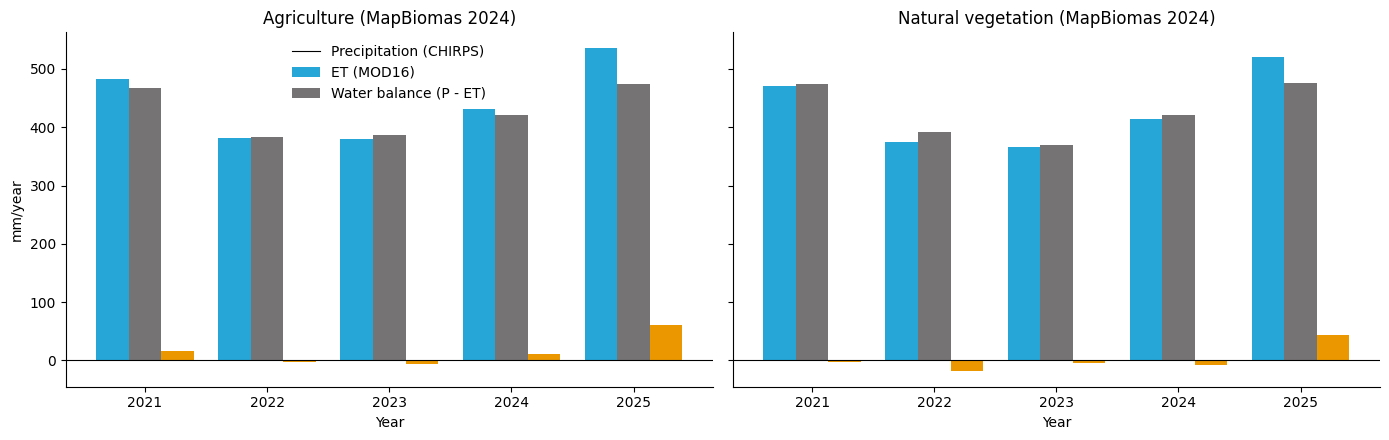

In [16]:
# P, ET y P - ET por año: agricultura (izquierda) y vegetación natural (derecha)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)

for ax, table, title in [(axes[0], annual_agri, "Agriculture"),
                         (axes[1], annual_veg, "Natural vegetation")]:
    table.plot.bar(ax=ax, rot=0, width=0.8, color=["#25a6d7", "#757373", "#eb9800"], legend=False)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{title} (MapBiomas {LULC_YEAR})")
    ax.set_xlabel("Year")
    ax.set_ylabel("mm/year")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].legend(["Precipitation (CHIRPS)", "ET (MOD16)", "Water balance (P - ET)"], frameon=False)
plt.tight_layout()
plt.show()

In [17]:
# Media de los últimos 5 años (mm/año): agricultura, vegetación natural y toda la cuenca
pd.DataFrame({
    "Agriculture": annual_agri.mean(),
    "Natural vegetation": annual_veg.mean(),
    "Whole watershed": annual.loc[END_YEAR - 4:].mean(),
}).round(0)

,Agriculture,Natural vegetation,Whole watershed
precipitation,442.0,429.0,581.0
ET,426.0,427.0,489.0
water_balance,16.0,2.0,92.0


**Cómo leerlo.** Compare las columnas. ¿La agricultura evapora más o menos que la
vegetación natural? ¿El P - ET anual es positivo (excedente) o negativo? Un balance negativo
significa que la superficie usa más agua de la que da la lluvia en ese año - la diferencia viene del
almacenamiento del suelo, del agua subterránea o del **riego**. Recuerde que ambos grupos reciben casi la misma
lluvia (CHIRPS es de ~5.5 km), así que las diferencias en P - ET vienen principalmente de la **ET**.

> **Nota.** Las máscaras están fijadas a un año (`LULC_YEAR`). Las parcelas cambian de un año a otro; para un
> análisis más estricto, use la banda de MapBiomas de cada año como máscara de ese año.

---

## 4.5 - Ejercicio

1. **Otro producto de precipitación.** Reemplace CHIRPS por **GSMaP**
   (`JAXA/GPM_L3/GSMaP/v8/operational`, banda `hourlyPrecipRate`, mm/**hora**) o por **ERA5-Land**
   (`ECMWF/ERA5_LAND/MONTHLY_AGGR`, banda `total_precipitation_sum`, en **metros** - multiplique por
   1000). Grafique los totales anuales de ambos productos lado a lado. ¿Qué tan diferentes son?
2. **Época húmeda frente a época seca.** Usando `df`, calcule el P - ET medio de diciembre-marzo y de
   mayo-septiembre. ¿Qué fracción de la lluvia anual cae en la época húmeda?
3. **Balance hídrico por cobertura del suelo.** Use el mapa de clasificación de la sesión 1 (o ESA WorldCover)
   y calcule la ET media anual de cada clase. ¿Qué clase evapora más?
4. **Registro más largo.** Cambie el período a 2001-2025. ¿La tendencia de la P mantiene el mismo signo?

**Entregable**: el notebook con los gráficos de las preguntas 1 y 4 y un párrafo
corto sobre lo que dice el balance P - ET acerca del agua disponible para el lago.

---

## Referencias

**Balance hídrico, precipitación y ET**

- Funk, C. et al. (2015). The climate hazards infrared precipitation with stations - a new
  environmental record for monitoring extremes. *Scientific Data*, 2, 150066.
  <https://doi.org/10.1038/sdata.2015.66> (CHIRPS)
- Kubota, T. et al. (2020). Global Satellite Mapping of Precipitation (GSMaP) products in the
  GPM era. In *Satellite Precipitation Measurement*, Springer.
  <https://doi.org/10.1007/978-3-030-24568-9_20>
- Huffman, G. J. et al. (2020). Integrated Multi-satellite Retrievals for the Global
  Precipitation Measurement (GPM) mission (IMERG). In *Satellite Precipitation Measurement*,
  Springer. <https://doi.org/10.1007/978-3-030-24568-9_19>
- Muñoz-Sabater, J. et al. (2021). ERA5-Land: a state-of-the-art global reanalysis dataset for
  land applications. *Earth System Science Data*, 13, 4349-4383.
  <https://doi.org/10.5194/essd-13-4349-2021>
- Mu, Q., Zhao, M., Running, S. W. (2011). Improvements to a MODIS global terrestrial
  evapotranspiration algorithm. *Remote Sensing of Environment*, 115(8), 1781-1800.
  <https://doi.org/10.1016/j.rse.2011.02.019> (MOD16)
- Senay, G. B. et al. (2013). Operational evapotranspiration mapping using remote sensing and
  weather datasets: a new parameterization for the SSEB approach. *JAWRA*, 49(3), 577-591.
  <https://doi.org/10.1111/jawr.12057> (SSEBop)
- Abatzoglou, J. T. et al. (2018). TerraClimate, a high-resolution global dataset of monthly
  climate and climatic water balance from 1958-2015. *Scientific Data*, 5, 170191.
  <https://doi.org/10.1038/sdata.2017.191>

**Datos y documentación**

- CHIRPS diario: <https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY>
- CHIRPS v3: <https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL>
- GSMaP v8: <https://developers.google.com/earth-engine/datasets/catalog/JAXA_GPM_L3_GSMaP_v8_operational>
- IMERG V07: <https://developers.google.com/earth-engine/datasets/catalog/NASA_GPM_L3_IMERG_V07>
- ERA5-Land mensual: <https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_MONTHLY_AGGR>
- MOD16A2GF: <https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD16A2GF>
- Conjuntos de datos de ET en GEE: <https://developers.google.com/earth-engine/datasets/tags/evapotranspiration>
- Landsat Collection 2 Provisional Actual ET (USGS):
  <https://www.usgs.gov/landsat-missions/landsat-collection-2-provisional-actual-evapotranspiration-science-product>

**Libro (acceso abierto)**

- Cardille, J.A., Crowley, M.A., Saah, D., Clinton, N.E. (eds.) (2023). *Cloud-Based Remote
  Sensing with Google Earth Engine: Fundamentals and Applications*. Springer.
  <https://www.eefabook.org/>